# Project.1_Pass-12b, Transaction Data






## Problem Definition


#### Description
State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

### Business Problem
We want to predict whether or not a future customer will make a transaction based on their transaction data. The goal might be to increase customer transactions by sending targeted ads/deals to customers who are not likely to make a transaction on a given day.

### Data Science Problem
Supervised binary classification problem.

## Data Collection/Sources


#### Description
Data source is transaction data in a 'csv' file from AWS S3. It contains nulls and identifier columns. Some 'var_x' feature columns contain all nulls. The target is binary (0 = unsuccessful, 1 = successful) its proportions are unbalanced. The full data set is used at the start (no row/column range constraints).

### Load Pandas, Numpy, and Matplotlib modules

In [1]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

import requests

from google.colab import userdata
import os

## Authenticate to Hugging Face


In [2]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:5]} ... {_[-3:]}"

'hf_as ... mJe'

In [3]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'ericbdf7'

In [4]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [5]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


Hint: A new version of huggingface_hub (2.2.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## Read parquet from Hugging Face


In [7]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/transactions.parquet"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/transactions.parquet'

In [8]:
df3 = pd.read_parquet( hf_url )
df3.shape


(180000, 51)

In [9]:
df3.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180000 entries, 0 to 179999
Data columns (total 5 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   target  180000 non-null  float64
 1   var_0   180000 non-null  float64
 2   var_1   180000 non-null  float64
 3   var_2   180000 non-null  float64
 4   var_4   180000 non-null  float64
dtypes: float64(5)
memory usage: 6.9 MB


## Exploratory Data Analysis


#### Description
In this section, the only classification model we know of is Gaussian Naive Bayes (GNB). I investigated whether the data set is appropriate for the GNB by checking if feature columns are normally distributed and if there is independence between all features (i.e., no significant correlation). The histogram shows a normal distribution, and the correlation matrix and heatmap show idependence. So this data set is appropriate for the GNB model.

Because I can see that the target is unbalanced, I anticipate balancing the data set later on. So I split the target out into 'successful' vs 'unsuccessful' transactions. No modifcations yet, just setting up those variables to use later on.

### Distribution of Features

''

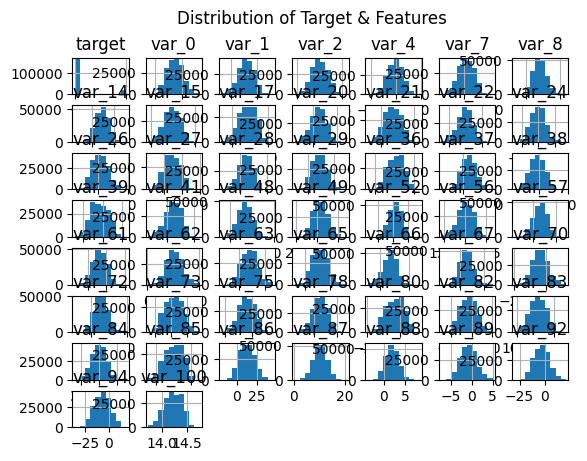

In [11]:
# Display a histogram; shows normal distribution for features (OK for GNB)
df3.hist()

plt.suptitle('Distribution of Target & Features')

;

### Correlation: Independence of Features

In [ ]:
# Calculate a correlation matrix
corr_mat = features.corr()

corr_mat

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
var_0,1.000000,-0.000892,-0.000225,-0.000269,-0.001320,0.002949,0.002901,-0.007758,-0.002799,-0.001353,...,-0.004960,-0.005451,-0.000716,0.004577,-0.004664,-0.001088,0.000236,0.001668,0.001837,0.001475
var_1,-0.000892,1.000000,0.006064,-0.000821,0.000783,-0.007127,-0.006180,-0.002585,-0.001663,0.001590,...,0.004265,0.002411,0.001484,-0.003859,-0.000485,0.003141,-0.006188,0.000071,-0.003682,0.003964
var_2,-0.000225,0.006064,1.000000,-0.003427,-0.000108,-0.001809,-0.002786,-0.001177,0.006360,0.004796,...,0.004890,0.002240,0.001980,-0.001161,0.003921,0.002087,-0.004422,-0.003418,-0.001565,0.002418
var_4,-0.000269,-0.000821,-0.003427,1.000000,-0.002750,0.003347,0.001377,-0.004732,-0.001814,-0.000539,...,0.000657,-0.005267,-0.004266,-0.004179,-0.004211,-0.002330,0.000254,0.001090,-0.000468,-0.002807
var_7,-0.001320,0.000783,-0.000108,-0.002750,1.000000,-0.003199,-0.003588,0.002329,0.004282,-0.001971,...,-0.000412,0.003262,0.002574,-0.001824,0.001186,0.002811,0.001306,0.000236,-0.000568,0.004575
var_8,0.002949,-0.007127,-0.001809,0.003347,-0.003199,1.000000,0.003472,-0.003858,-0.002727,-0.003417,...,-0.008394,-0.004254,-0.002446,0.001117,-0.003713,-0.003929,0.003837,0.003422,0.003204,0.000821
var_14,0.002901,-0.006180,-0.002786,0.001377,-0.003588,0.003472,1.000000,-0.007115,-0.004249,-0.001595,...,-0.002214,-0.002179,-0.003054,-0.000160,-0.000504,-0.004046,0.003136,0.005715,0.001501,-0.000106
var_15,-0.007758,-0.002585,-0.001177,-0.004732,0.002329,-0.003858,-0.007115,1.000000,0.002467,0.003584,...,0.000581,0.006633,0.004569,-0.001573,0.003251,0.003066,-0.001541,-0.003719,-0.002825,0.004247
var_17,-0.002799,-0.001663,0.006360,-0.001814,0.004282,-0.002727,-0.004249,0.002467,1.000000,0.001476,...,0.005578,0.001237,0.000210,-0.002714,0.004149,-0.002182,-0.002642,-0.001968,-0.004100,-0.000822
var_20,-0.001353,0.001590,0.004796,-0.000539,-0.001971,-0.003417,-0.001595,0.003584,0.001476,1.000000,...,-0.001476,0.003107,0.001610,0.001186,0.004265,0.001449,-0.004506,-0.003241,-0.000988,0.001734


Text(77.92222222222227, 0.5, 'Features')

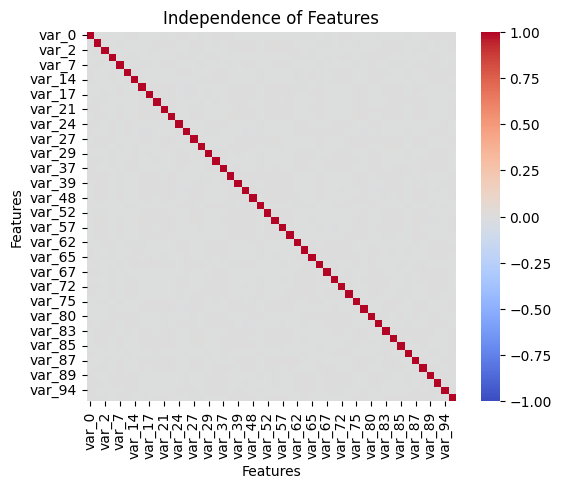

In [ ]:
# Heatmap of the correlation matrix to see independence (shows that each feature is perfectly correlated with itself)
sns.heatmap(
    corr_mat,
    square=True,
    annot=False,
    fmt='2f',
    cbar=True,
    cmap='coolwarm',
    vmin=-1,vmax=1
)

plt.title('Independence of Features')
plt.xlabel('Features')
plt.ylabel('Features')

### Create Two Dataframes (Copies, Not Slices)
1. Successful Transactions
1. Unsuccessful Transactions

In [ ]:
# Create a dataframe of successful transactions
successful_df = df[df['target'] == 1].copy()

# Create a dataframe of unsuccessful transactions
unsuccessful_df = df[df['target'] == 0].copy()

## Data Processing



#### Description
This section involves building cross validation (CV) models on our unbalanced and balanced data set, then presenting the results by displaying heatmaps of confusion matrixes, classification reports, and accuracy comparisions. The method goes as follows: empty GNB model, setting up a train-test split for our target and features, verifying the train-test-split, fitting (training) the model using training subsets, running predictions using the testing subset, and reporting the accuracy. Insights from the CVs are included here.

Single CV (unbalanced)
- Better at predicting unsuccessful vs. successful
- Low false negative rate when compared to true negatives
- False positive rate is 50% lower than the true positives (33% of the time)

Multi CV (unbalance)
- Accuracy score similar to single CV (unbalanced).

Multi CV (balanced data set)
- Predicts unsuccessful vs. successful transactions evenly
- Predicts incorrectly 25% of the time
- False positive rate is 12.5% of the time
- False negative rate is 12.5% of the time




### Single Cross Validation ( CV )

#### Define an empty Gaussian Naïve Bayes model using Sklearn

In [ ]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### Divide the two data sets (target/features) into training and testing subsets, i.e. train-test split.

In [ ]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
     features,
     target,
     test_size=0.25
)

In [ ]:
# Verify shape of each data set from Train Test Split
for i in [ X_train, X_test, y_train, y_test ]:
  print(i.shape)
  print(type(i))

(135000, 50)
<class 'pandas.core.frame.DataFrame'>
(45000, 50)
<class 'pandas.core.frame.DataFrame'>
(135000,)
<class 'pandas.core.series.Series'>
(45000,)
<class 'pandas.core.series.Series'>


#### Train ( fit ) the model using the training subset of the dataset.

In [ ]:
# Train ( fit ) the model
modelGNB.fit( (X_train), y_train)

GaussianNB()

#### Test the model ( predict ) using the testing subset of the dataset.

In [ ]:
# Make predicitons using the model
pred_results = modelGNB.predict(X_test)
pred_results * 1000

array([   0., 1000.,    0., ...,    0.,    0.,    0.])

#### Calculate and report the accuracy.

In [ ]:
# Display accuracy
acc = metrics.accuracy_score( y_test,pred_results )
acc * 100

91.13777777777777

#### Confusion matrix and heatmap

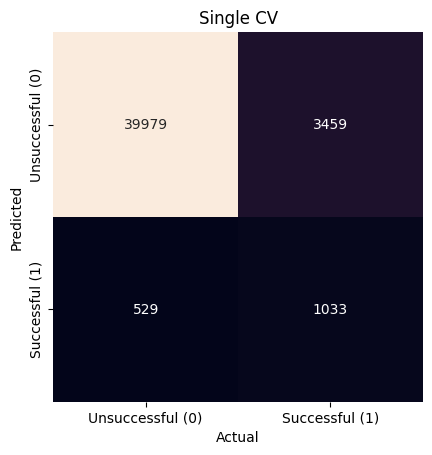

In [ ]:
# Display a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "d",
    cbar = False,
    xticklabels=['Unsuccessful (0)', 'Successful (1)'],
    yticklabels=['Unsuccessful (0)', 'Successful (1)']
)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Single CV');

#### Classification Report (sklearn.metrics.classification_report).

In [ ]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40508
         1.0       0.66      0.23      0.34      4492

    accuracy                           0.91     45000
   macro avg       0.79      0.61      0.65     45000
weighted avg       0.89      0.91      0.89     45000



### Multiple Cross-Validation (CV)

In [ ]:
# Multiple CV loop
n = 100
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features, target, test_size=0.25, random_state=None
    )

    # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    results[i] = metrics.accuracy_score(y_test, pred_results)

results

array([0.91217778, 0.90962222, 0.91195556, 0.91095556, 0.91166667,
       0.90835556, 0.91028889, 0.91182222, 0.91015556, 0.91008889,
       0.90944444, 0.91133333, 0.91266667, 0.91128889, 0.91097778,
       0.91115556, 0.90875556, 0.91193333, 0.90871111, 0.91      ,
       0.91053333, 0.91062222, 0.91268889, 0.90962222, 0.91175556,
       0.90911111, 0.91257778, 0.91062222, 0.91031111, 0.90953333,
       0.90922222, 0.91188889, 0.90915556, 0.90904444, 0.91082222,
       0.91224444, 0.91086667, 0.91091111, 0.91171111, 0.90906667,
       0.91206667, 0.90913333, 0.91311111, 0.91206667, 0.90986667,
       0.91093333, 0.91055556, 0.91037778, 0.91113333, 0.91202222,
       0.91075556, 0.91202222, 0.91077778, 0.90813333, 0.91302222,
       0.91191111, 0.9112    , 0.91088889, 0.91028889, 0.913     ,
       0.91282222, 0.91311111, 0.91197778, 0.90886667, 0.91066667,
       0.91175556, 0.91188889, 0.91248889, 0.91077778, 0.91106667,
       0.91017778, 0.91233333, 0.91      , 0.91097778, 0.91262

#### Classification Report

In [ ]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.92      0.99      0.95     40514
         1.0       0.68      0.23      0.34      4486

    accuracy                           0.91     45000
   macro avg       0.80      0.61      0.65     45000
weighted avg       0.90      0.91      0.89     45000



### Accuracy Comparison (single CV vs. multi CV)

In [ ]:
# Compare the accuracies by creating variables for each
acc_single_cv = acc
acc_multi_cv = results[i]

display('Single CV:', acc_single_cv)
display('Multi CV:', acc_multi_cv)

'Single CV:'

0.9113777777777777

'Multi CV:'

np.float64(0.9120444444444444)

### Balance Dataset

The training data is very skewed towards non-successful transactions (about 90% of the training data has ‘target’==0).

Remove enough non-successful transaction rows so that your remaining training data is 50%/50% split between successful and non-successful transactions.

In [ ]:
# Display value counts of the target
df['target'].value_counts()

,count
target,
0.0,161960
1.0,18040


In [ ]:
# Place minority class in one dataframe (done above)
successful_df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
57,1.0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264,15.6935,2.6980,4.3336,...,11.2059,4.0237,5.8905,12.4865,10.1419,2.3370,-3.1553,-12.6928,-3.0833,14.1895
125,1.0,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863,21.4162,2.8672,6.4550,...,10.8110,3.9190,7.4971,35.7428,9.6149,2.2257,-0.5949,-9.4101,-15.6555,14.4514
151,1.0,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962,11.4553,2.6735,2.1990,...,11.6326,3.9193,5.0366,37.1453,17.0341,0.9987,-3.0163,-1.5409,-7.6389,14.1725
155,1.0,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781,16.9541,2.0573,5.5008,...,11.2981,4.1316,7.2193,-1.8139,1.8190,2.5720,0.6780,6.4045,1.1754,14.1347
302,1.0,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025,22.4577,3.0906,16.2501,...,11.5449,4.0001,9.0639,11.8805,9.4678,1.0561,-0.2107,9.8815,-2.9328,14.0933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049783,1.0,3.1286,15.0751,21.3962,11.3161,-10.0493,6.3525,25.4931,2.6605,7.2691,...,10.9172,4.1120,4.6540,9.1151,7.8918,2.5714,1.0304,5.2623,-0.6030,14.1993
1049818,1.0,15.2934,17.5721,5.8949,-4.0233,5.8840,7.3892,11.3932,2.7062,6.9666,...,11.1665,3.9652,7.4879,-7.9060,10.7256,0.8941,-3.5967,6.3976,0.5778,14.5067
1049978,1.0,7.4751,17.0314,5.0834,-1.5220,-2.4913,6.7953,10.7764,2.9049,2.6145,...,11.6605,3.6716,8.5965,19.2145,8.2747,4.0945,-3.0127,2.9477,-2.3696,14.4122
1049983,1.0,5.2746,14.4095,17.7709,-2.9855,-0.8515,6.5097,11.5599,2.9677,0.0507,...,11.8870,3.7776,6.9876,3.3482,9.7469,-0.3425,-2.5684,14.5286,-5.4146,14.4388


In [ ]:
# Put majority class into its own dataframe (done above)
unsuccessful_df

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,11.8011,3.9677,9.5382,-8.4394,5.5043,2.2732,1.6362,11.1077,-12.6465,14.0618
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,11.8294,3.8887,8.8591,6.1482,8.5833,2.8432,1.8434,-2.0111,-3.6166,14.4520
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,11.7464,4.0017,5.8179,10.4951,12.4494,2.8009,0.3394,13.9424,-15.5776,14.1222
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,11.5481,3.9809,8.2247,21.2257,6.9931,3.3939,-2.3905,3.7943,5.6184,14.0619
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,10.8981,4.1808,9.4220,1.8563,10.5738,1.2409,-1.3888,-5.6677,-1.8961,14.0275
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1049988,0.0,10.7453,13.3217,15.4001,4.0421,1.3116,6.3990,13.9387,2.9627,13.6450,...,11.6062,3.9162,9.7054,15.2405,10.6480,0.5372,0.4014,4.8258,-8.2380,14.0328
1049990,0.0,7.9632,20.4650,10.7295,2.9322,5.0267,7.1953,10.0695,3.0732,11.0135,...,12.1000,4.2019,7.1249,14.6591,10.2705,3.5833,2.5588,10.4219,-19.7158,14.0582
1049993,0.0,5.0862,14.4785,17.3709,-2.4732,-2.5987,6.6798,3.0420,2.4057,18.2729,...,10.9960,3.9637,8.0217,11.0449,9.3100,1.0545,-2.8770,-2.8052,-13.7290,14.3794
1049997,0.0,8.9941,13.4127,3.9567,3.5744,1.6614,6.1486,12.0996,2.5439,10.2936,...,10.5067,4.0642,8.3381,17.9081,12.3357,2.6530,-1.2359,2.0836,-18.6168,14.0689


In [ ]:
# Create downsample of majority class in another data frame
majority_downsampled = unsuccessful_df.sample(
    n=len(successful_df),
    random_state=42
)

# Display the downsample to verify
print("Minority class:")
print(successful_df['target'].value_counts())

print("Downsampled majority class:")
print(majority_downsampled['target'].value_counts())

Minority class:
target
1.0    18040
Name: count, dtype: int64
Downsampled majority class:
target
0.0    18040
Name: count, dtype: int64


In [ ]:
# Combine the dataframes
balanced_df = pd.concat([successful_df, majority_downsampled])

# Reset the index
balanced_df = balanced_df.reset_index(drop=True)

In [ ]:
# Verify target counts are now equal
balanced_df['target'].value_counts()

,count
target,
1.0,18040
0.0,18040


#### Backup #3

In [ ]:
# Create 3rd backup
df_bak_3 = df.copy()

In [ ]:
# Restore from backup
df = df_bak_3.copy()

#### Repeat Multi Cross-Validation

In [ ]:
# Split data frame into target and features using balanced dataset
target_col = 'target'
target_balanced_df = balanced_df[ target_col]
features_balanced_df = balanced_df.drop(columns=[target_col])

In [ ]:
# Verify the balanced target
target_balanced_df

,target
0,1.0
1,1.0
2,1.0
3,1.0
4,1.0
...,...
36075,0.0
36076,0.0
36077,0.0
36078,0.0


In [ ]:
# Verify the features
features_balanced_df

,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,var_20,...,var_83,var_84,var_85,var_86,var_87,var_88,var_89,var_92,var_94,var_100
0,8.9078,12.1321,9.4707,-5.8102,0.4521,7.1264,15.6935,2.6980,4.3336,12.5243,...,11.2059,4.0237,5.8905,12.4865,10.1419,2.3370,-3.1553,-12.6928,-3.0833,14.1895
1,6.2143,20.0990,23.5009,-0.8917,-3.9167,6.6863,21.4162,2.8672,6.4550,16.3479,...,10.8110,3.9190,7.4971,35.7428,9.6149,2.2257,-0.5949,-9.4101,-15.6555,14.4514
2,8.9083,12.1117,18.0359,-4.9628,10.1135,6.8962,11.4553,2.6735,2.1990,11.1778,...,11.6326,3.9193,5.0366,37.1453,17.0341,0.9987,-3.0163,-1.5409,-7.6389,14.1725
3,6.5612,13.9638,5.1980,12.1092,8.4874,6.4781,16.9541,2.0573,5.5008,0.3052,...,11.2981,4.1316,7.2193,-1.8139,1.8190,2.5720,0.6780,6.4045,1.1754,14.1347
4,4.4616,9.7572,12.9317,7.6485,0.6382,5.8025,22.4577,3.0906,16.2501,7.3399,...,11.5449,4.0001,9.0639,11.8805,9.4678,1.0561,-0.2107,9.8815,-2.9328,14.0933
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36075,4.4165,14.1108,16.9036,-1.7004,0.5204,6.5962,-2.6199,3.4255,0.1414,19.1131,...,11.4631,3.8506,9.0249,20.1304,11.3339,0.5109,3.3331,-13.1584,4.6673,14.4395
36076,9.6312,17.9872,6.1934,-4.5551,5.6778,7.0958,8.8347,2.8895,2.4021,-2.5986,...,10.8018,4.2457,8.4013,6.5742,13.5109,2.7851,-0.1141,-8.5076,-18.8957,14.2713
36077,4.6518,12.6792,19.3345,-5.9933,1.5722,6.7321,18.5658,3.2414,11.3328,-5.9847,...,11.1230,4.0996,7.5840,6.1360,10.7843,3.0418,-0.4006,-9.1780,2.4831,13.9453
36078,5.5259,17.4647,19.3796,7.8173,-1.7046,7.8236,19.1841,3.0881,16.8589,4.4127,...,11.1961,4.0940,6.2651,-10.3256,12.5128,2.9950,-2.7132,-14.1962,-11.4152,14.3034


In [ ]:
# Multiple CV loop
n = 100
balanced_df_results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(
        features_balanced_df, target_balanced_df, test_size=0.25, random_state=None
    )

   # Create an empty GNB model
    modelGNB = GaussianNB()

    # Train ( fit ) the model
    modelGNB.fit( (X_train), y_train)

    # Make predicitons using the model
    pred_results = modelGNB.predict(X_test)

    # calculate the accuracy
    balanced_df_results[i] = metrics.accuracy_score(y_test, pred_results)

balanced_df_results

array([0.74368071, 0.75731707, 0.75310421, 0.74611973, 0.75631929,
       0.75254989, 0.75986696, 0.75099778, 0.75421286, 0.74767184,
       0.75133038, 0.75698448, 0.75055432, 0.75631929, 0.75509978,
       0.75487805, 0.75321508, 0.75665188, 0.75687361, 0.75465632,
       0.74855876, 0.75443459, 0.7594235 , 0.75      , 0.75365854,
       0.75875831, 0.75576497, 0.74977827, 0.74711752, 0.74988914,
       0.75044346, 0.74933481, 0.75554324, 0.7594235 , 0.75033259,
       0.75254989, 0.75044346, 0.75299335, 0.76097561, 0.75898004,
       0.75620843, 0.75155211, 0.76341463, 0.75099778, 0.75864745,
       0.74667406, 0.75543237, 0.75332594, 0.75155211, 0.75277162,
       0.75498891, 0.76086475, 0.75454545, 0.75299335, 0.74944568,
       0.75776053, 0.75476718, 0.75011086, 0.74578714, 0.75532151,
       0.75343681, 0.75698448, 0.75388027, 0.75798226, 0.75399113,
       0.74611973, 0.75698448, 0.76430155, 0.75133038, 0.75266075,
       0.76241685, 0.75388027, 0.75487805, 0.75498891, 0.75465

#### Mean accuracy for balanced dataset

In [ ]:
# Report what your mean accuracy for this balanced data set
display(balanced_df_results[i])

np.float64(0.7546563192904656)

In [ ]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.74      0.78      0.76      4484
         1.0       0.77      0.73      0.75      4536

    accuracy                           0.75      9020
   macro avg       0.76      0.75      0.75      9020
weighted avg       0.76      0.75      0.75      9020



#### Histogram of the accuracy scores

''

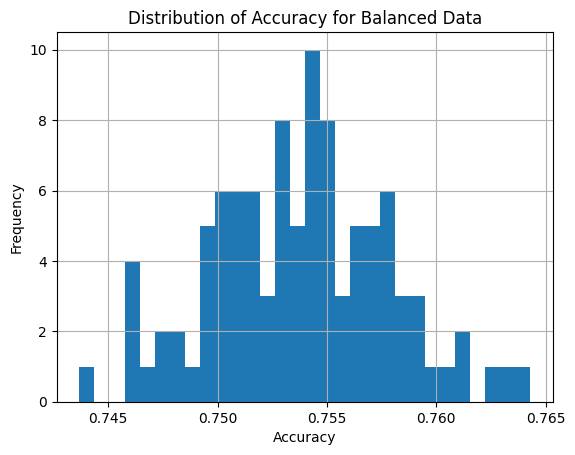

In [ ]:
# Display a histogram of the balanced dataset
pd.Series(balanced_df_results).hist(bins=30)

plt.title('Distribution of Accuracy for Balanced Data')
plt.xlabel('Accuracy')
plt.ylabel('Frequency')
;

What do you notice about the distribution of accuracy scores?

There is a positive skew.

#### Confusion Matrix and Heatmap

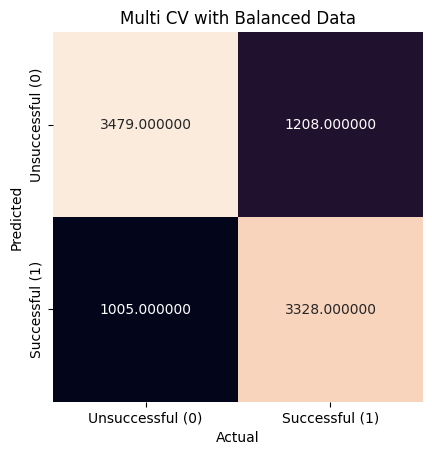

In [ ]:
# Displaly a confusion matrix and heatmap
mat =  metrics.confusion_matrix(
    y_test,
    pred_results,
)

sns.heatmap( mat.T,
    square=True,
    annot=True,
    fmt = "d",
    cbar = False,
    xticklabels=['Unsuccessful (0)', 'Successful (1)'],
    yticklabels=['Unsuccessful (0)', 'Successful (1)']
)
plt.title('Multi CV with Balanced Data')
plt.xlabel('Actual')
plt.ylabel('Predicted');

#### Classification Report

In [ ]:
# Display a classification report
print(metrics.classification_report(y_test, pred_results))

              precision    recall  f1-score   support

         0.0       0.74      0.78      0.76      4484
         1.0       0.77      0.73      0.75      4536

    accuracy                           0.75      9020
   macro avg       0.76      0.75      0.75      9020
weighted avg       0.76      0.75      0.75      9020



What do you notice? That is, how do the different metrics compare to each other?

## Data Visualization/Communication of Results


#### Description
This section displays a histogram of the results after cleaning, balancing and comparing insights from CVs. Below, I chose to display a frequency distribution of the accuracy scores from running a multi CV with the balanced data set because it shows a predictable pattern. It more evenly predicts a successful vs. unsuccessful transaction despite a lower mean accuracy compared to before balancing the data set.

### Data Visualization

''

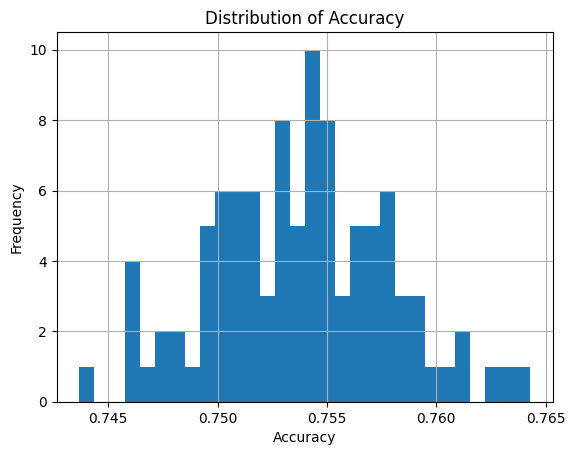

In [ ]:
# Display a histagram of the results
pd.Series(balanced_df_results).hist(bins=30)

plt.title('Distribution of Accuracy')
plt.xlabel('Accuracy')
plt.ylabel('Frequency')
;

## Communication of Results



#### Description
This section contains my conclusions which are insights from running our models before and after balancing the dataset. It also contains recommendations for future work including using alternative metrics and alternative classification models.

### Conclusion

- Accuracy alone doesn’t necessarily mean model is good at identifying successful transactions
- Higher accuracy may indicate the model is good at predicting the majority class (unsuccessful transactions)
- Accuracy dropped from 91% to 75% after balancing the data set
- Balanced data set provides more even representation
- Single CV not great at predicting a successful transaction.
- Multi CV more evenly predicts a successful vs. unsuccessful transaction despite a lower mean accuracy.

### Future work

Alternative metrics besides accuracy

- Precision, recall, and F1-score

Alternative classification models

- Predicts successful and unsuccessful transactions more effectively
